<a href="https://colab.research.google.com/github/AlsouAR/Deep-Learning/blob/main/%22hw_1_game_of_thrones_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

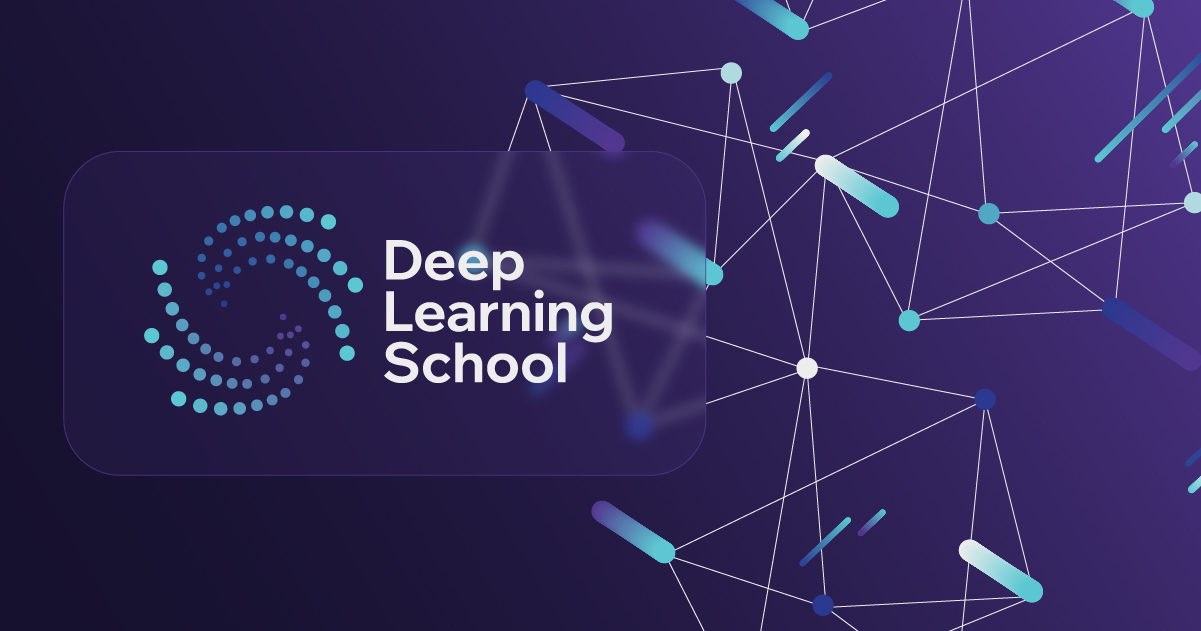

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Библиотека sklearn и классификация с помощью KNN</b></h1>

## Описание домашнего задания

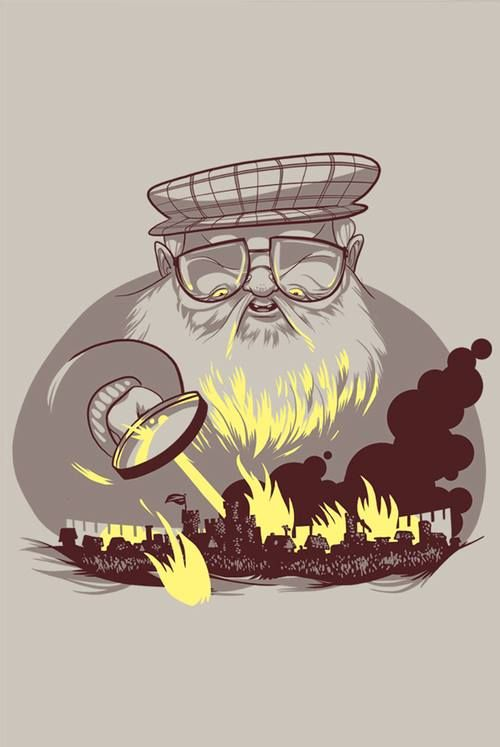

В данном задании вы будете работать с датасетом о персонажах из вселенной Игры Престолов [A Wiki of Ice and Fire](http://awoiaf.westeros.org/). Вам предстоит предсказать, кто из персонажей умрет, а кто останется вживых.



Описание данных:

* **name**: Имя персонажа

* **Title**: Социальный статус или знатность

* **House**: Дом, к которому принадлежит персонаж

* **Culture**: Социальная группа, к которой принадлежит персонаж

* **book1/2/3/4/5**: Появление персонажа в книге

* **Is noble**: Знатность персонажа, основанное на титуле

* **Age**: Отсчет времени: 305 AC

* **male**: Мужчина или женщина

* **dateOfBirth**: дата рождения

* **Spouse**: Имя супруги\а персонажа

* **Father**: Имя отца персонажа

* **Mother**: Имя матери персонажа

* **Heir**: Имя наследника персонажа

* **Is married**: Represents whether the character is married

* **Is spouse alive**: Represents whether character's spouse is alive

* **Is mother alive:** Жива ли мать персонажа

* **Is heir alive:** Жив ли наследник персонажа

* **Is father alive:** Указывает, жив ли отец персонажа

* **Number dead relations:** Количество умерших персонажей, с которыми персонаж связан

* **Popularity score:** Количество внутренних входящих и исходящих ссылок на страницу персонажей в вики http://awoiaf.westeros.org

Целевая переменная:
* **isAlive**: жив ли персонаж в книге

Оценивание:

Баллы считаются следующим образом:

1) $1.00 \geqslant score \geqslant 0.65$ --- 5 баллов

2) $0.65 > score \geqslant 0.50$ --- 4 балла

3) $0.50 > score \geqslant 0.45$ --- 3 балла

4) $0.45 > score \geqslant 0.40$ --- 2 балла

5) $0.40 > score \geqslant 0.35$ --- 1 балл

6) $0.35 > score$ --- 0 баллов

## Часть 1. Анализ и предобработка данных

Здесь вам необходимо сделать все шаги, которые обсуждались в первой части семинара.
* Предобработка данных
  * Обработка пропущенных данных
  * Создание новых признаков
  * Удаление ненужных столбцов
* Анализ данных
  * Анализ целевой переменной
  * Анализ признаков
  * Анализ влияния признаков на целевую переменную
* Подготовка данных для обучения модели

Загружаем датасет

In [ ]:
!gdown 1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3 # test dataset
!gdown 1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v # train dataset

Downloading...
From: https://drive.google.com/uc?id=1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3
To: /content/game_of_thrones_test.csv
100% 37.3k/37.3k [00:00<00:00, 59.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v
To: /content/game_of_thrones_train.csv
100% 138k/138k [00:00<00:00, 59.9MB/s]


**Задание 1.1.** Импортируйте библиотеки pandas, matplotlib, seaborn

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

**Задание 1.2.** Загрузите датасет в Pandas DataFrame при помощи функции `read_csv`. Вместо дефолтных наименований строк `0,1,...`, при помощи параметра `index_col`, сделайте значения колонки `S.No` наименованиями строк:

In [ ]:
data = pd.read_csv('/content/game_of_thrones_train.csv', index_col='S.No')

In [ ]:
data.head()

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity,isAlive
S.No,,,,,,,,,,,,,,,,,,,,,
1,Viserys II Targaryen,NaN,1,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,Aegon IV Targaryen,NaN,NaN,...,1.0,0.0,0.0,NaN,0,0,NaN,11,0.605351,0
2,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,House Frey,Perra Royce,...,NaN,NaN,NaN,1.0,1,1,97.0,1,0.896321,1
3,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,House Swyft,NaN,...,NaN,NaN,NaN,NaN,0,1,NaN,0,0.267559,1
4,Aemma Arryn,Queen,0,NaN,82.0,NaN,NaN,NaN,House Arryn,Viserys I Targaryen,...,NaN,NaN,NaN,0.0,1,1,23.0,0,0.183946,0
5,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,House Santagar,Eldon Estermont,...,NaN,NaN,NaN,1.0,1,1,29.0,0,0.043478,1


Посмотрите, какие типы данных представлены в нашем датасете

Знакомый нам метод describe() возвращает различную информацию для столбцов с числовыми типами данных, и с типами данных *object*

Давайте посмотрим на вывод для типа данных *object*. Для этого:
- сначала применим метод describe(). Укажем в качестве аргумента тип данных столбцов, статистику по которым мы хотим посмотреть (см. https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html)
- для удобства восприятия транспонируем таблицу

In [ ]:
data.describe(include = 'object').T

,count,unique,top,freq
name,1557,1557,Melara Hetherspoon,1
title,717,195,Ser,306
culture,488,51,Northmen,94
mother,18,16,Rhaenyra Targaryen,2
father,22,19,Daemon Targaryen,2
heir,21,20,Jaehaerys Targaryen,2
house,1176,315,House Frey,89
spouse,200,186,Walder Frey,6


Теперь давайте посмотрим на столбцы с числовыми типами данных. Дополните код ниже. Для удобства восприятия мы транспонировали таблицу и ограничили вывод тремя столбцами - количество строк без NaN, максимальное и минимальное значение (о кастомизации вариантах вывода describe() вы можете почитать в документации по ссылке выше).


In [ ]:
data.describe(include = ['number']).T[['count', 'min', 'max']]

,count,min,max
male,1557.0,0.0,1.0
dateOfBirth,279.0,-25.0,299.0
book1,1557.0,0.0,1.0
book2,1557.0,0.0,1.0
book3,1557.0,0.0,1.0
book4,1557.0,0.0,1.0
book5,1557.0,0.0,1.0
isAliveMother,18.0,0.0,1.0
isAliveFather,22.0,0.0,1.0
isAliveHeir,21.0,0.0,1.0


Так мы проверим, есть ли в данных неадекватнные значения.   Большинство числовых столбцов - это числа от 0 до 1. Отрицательные значения `dateOfBirth` не являются ошибкой. Значения age и `numDeadRelations` также выглядят адекватными. Можно переходить к дальнейшим шагам анализа (анонс - а в тестовых данных нас будет ждать сюрприз).

**Задание 1.3.** Предобработка (очистка) данных.

В нашем домашнем задании все пропуски в данных (missing values) уже закодированы как NaN. Проанализируйте, в каких колонках и как часто встречаются NaN значения. Далее вам надо будет принять решение, как их обрабатывать.

In [ ]:
data.isna().sum(axis=0)

,0
name,0
title,840
male,0
culture,1069
dateOfBirth,1278
mother,1539
father,1535
heir,1536
house,381
spouse,1357


В этом задании удалять строки с NaN (dropna) мы не будем по следующим причинам:
- в обучающем датасете много признаков с большим количество пропусков. Если удалять все строки с NaN, то размер выборки сильно уменьшится. Мы потеряем много данных, которые можно было бы использовать для построения более точной модели.
- тестовом датасете также много признаков с NaN (вы можете в этом убедиться, если скачаете датасет и совершите с ним те же действия, что выше проделали с обучаюшим датасетом). Поэтому нам все-равно придется придумать способ кодировать NaN, чтобы модель делала прогнозы для всех персонажей из тестового датасета. Для этого нам потребуется сохранять, а не удалять данные в обучающем датасете.     



Как вы могли заметить, в наших данных очень много пропущенных значений, причём в некоторых случая пропущена **большая** часть значений. Поэтому заполнять по умолчанию медианой/средним/модой в данном случае - не самый лучший способ (однако, это довольно часто используемый метод заполнения, который может пригодиться вам в будущем)

Ниже мы посмотрим, как можно работать с признаками с большим количеством пропущенных значений.

**Задание 1.4.** Числовые признаки

У нас есть **признак popularity**. Постройте гистограмму распределения данного признака с количеством интервалов (bins), равным 50 (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html)

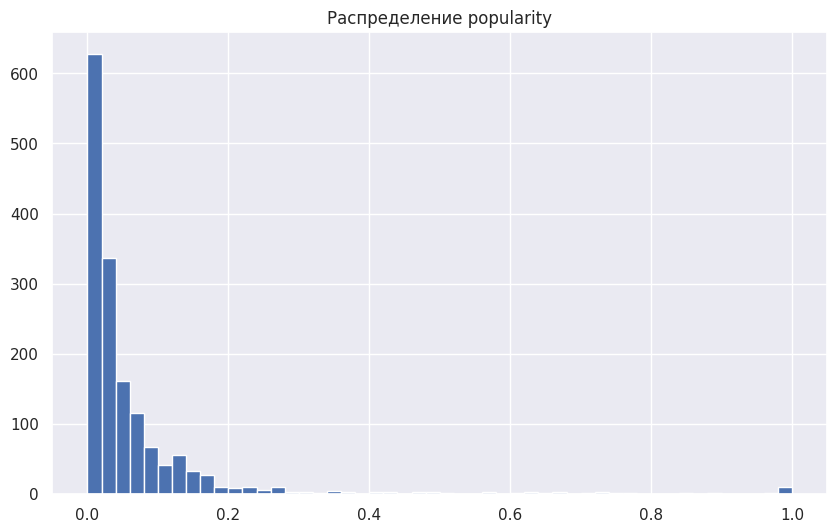

In [ ]:
data.hist(column='popularity', bins=50, figsize=(10, 6))
plt.title('Распределение popularity')
plt.show()

Распределение сильно несимметрично. Можно преобразовать данный признак, например, по формуле `np.log10(data["popularity"]*M+1)` (добавляем 1 ради логарифма, так как для некоторых персонажей `popularity==0`). В качестве M можно попробовать, например, M=100 или другое число.

При желании для `popularity` вы можете использовать свой способ шкалирования признаков с несимметричным распределением.


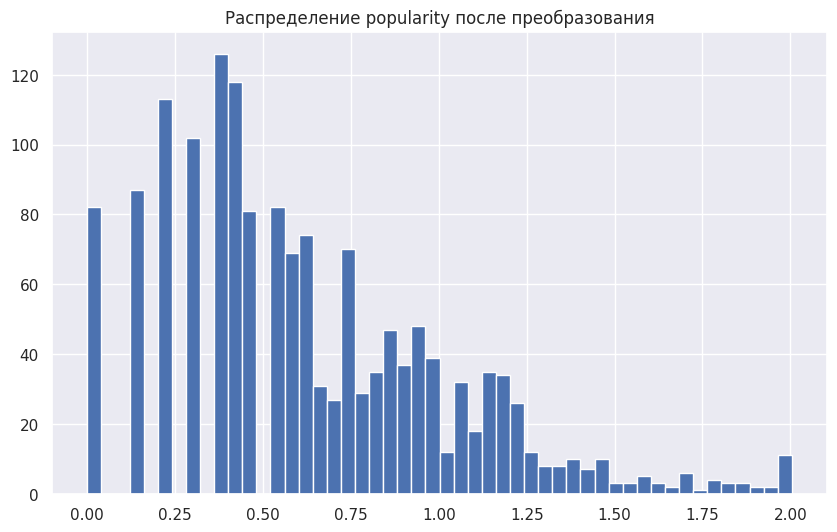

In [ ]:
M = 100
data['popularity_log'] = np.log10(data['popularity'] * M + 1)
data.hist(column='popularity_log', bins=50, figsize=(10, 6))
plt.title('Распределение popularity после преобразования')
plt.show()

In [ ]:
data = data.drop(columns=['popularity'])

В качестве альтернативного подхода вы можете попробовать дискретизацию признака popularity на основе квантилей (quantile binning), используя функцию qcut() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.qcut.html). В этом случае вы преобразуете числовой признак popularity в категориальный, для которого в дальнейшем надо будет применить one-hot кодирование.

Теперь давайте обработаем **признак numDeadRelations**.
Посмотрите на частотное распределение этого признака. Лишь для малого числа персонажей `numDeadRelations>0`.

Создайте признак `boolDeadRelations`. Давайте упростим признак `numDeadRelations`, и просто поделим людей на тех, у кого были хоть какие то отношения с мертвыми персонажами, т.е. `numDeadRelations > 0`, и те, у которых не было, т.е. `numDeadRelations = 0`.

Посмотрим частотное распределение признака

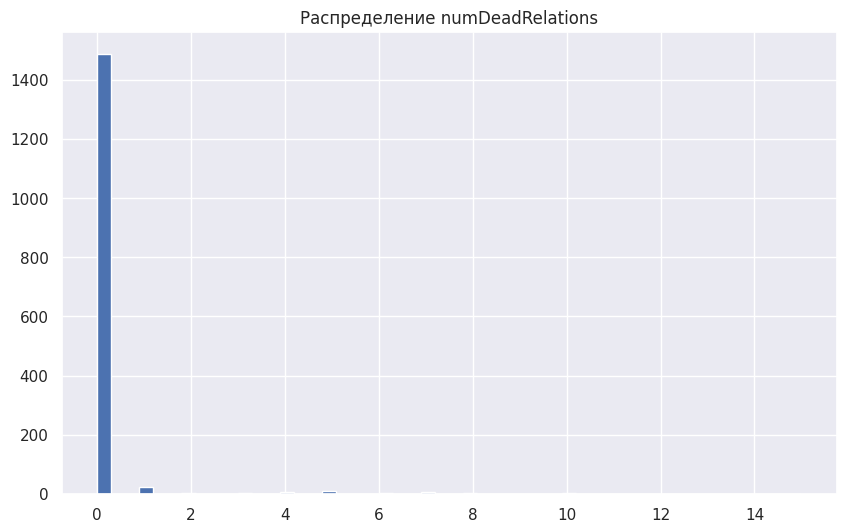

In [ ]:
data.hist(column='numDeadRelations', bins=50, figsize=(10, 6))
plt.title('Распределение numDeadRelations')
plt.show()

То есть упрощаем признок до бинарного (пропущенных значений тут не было)
1) numDeadRelations > 0 это 1
2) numDeadRelations = 0 это 0

In [ ]:
data['boolDeadRelations'] = (data['numDeadRelations'] > 0).astype(int)

In [ ]:
data = data.drop(columns=['numDeadRelations'])

посмотрим что получилось

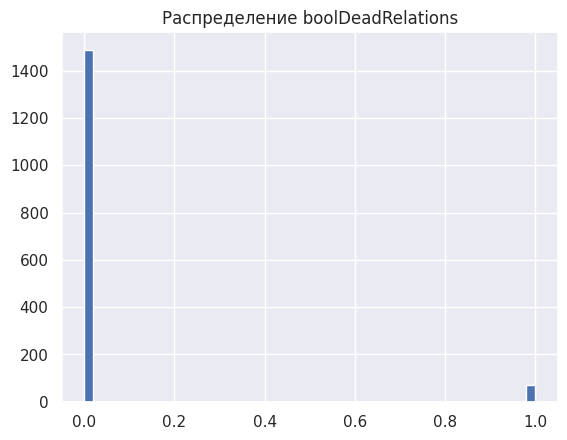

In [ ]:
data.hist(column='boolDeadRelations', bins=50)
plt.title('Распределение boolDeadRelations')
plt.show()

Наконец, давайте посмотрим на **признак age**. В нем очень много пропущенных значений. Для того, чтобы использовать в модели информацию о возрасте персонажа, мы создадим два новых признака: `age_value` и `age_no_data`

- Там где возраст указан, age_value принимает значение `age`, а `age_no_data` - значение 0.
- Там где возраст не указан, `age_value` принимает значение 0, а `age_no_data` - значение 1.  

Фактически, в переменной `age` мы заменяем NaN на 0, но одновременно добавляем в модель еще один бинарный признак `age_no_data`, несущий информацию о том, у каких персонажей не был указан возраст:        

In [ ]:
data['age_value'] = [0 if np.isnan(x) else x for x in data['age']]
data['age_no_data'] = [1 if np.isnan(x) else 0 for x in data['age']]

In [ ]:
data = data.drop(columns=['age'])

Этот способ чем-то похож на работу с категориальной переменными с пропущенными значениями, когда мы добавляем еще одну категорию no_data и заменяем NaN на значение этой категории.

Если вы заходите похожим образом образом обработать признак `dateOfBirth`, **обратите внимание**, что у одних и тех же персонажей не указан и возраст, и год рождения.
То есть созданные признаки `age_no_data` и `dateOfBirth_no_data` будут полностью совпадать, и в модель надо будет включать только один из признаков: или `age_no_data`, или `dateOfBirth_no_data`.

In [ ]:
data = data.drop(columns=['dateOfBirth'])

**Задание 1.5.** Категориальные признаки с большим количеством категорий

**Признак culture** содержит информацию о принадлежности к одному из народов во вселенной Игры Престолов.

Давайте посмотрим, какие значения принимает данный признак. По умолчанию метод `value_counts()` игнорирует пропуски в данных, поэтому используем этот метод с параметром **dropna** со значением **False** (см. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.value_counts.html)

In [ ]:
data['culture'].value_counts(dropna=False)

,count
culture,
NaN,1069
Northmen,94
Ironborn,91
Free Folk,45
Braavosi,39
Valyrian,28
Ghiscari,17
Dornish,17
Dothraki,17


Из полученного частотного распределения видно, что для большого числа персонажей значения данного признака не указаны. Также есть много редких значений признака, которые в выборке повторяются один или несколько раз. Причина отчасти в том, что один и тот же народ упоминается в нашем датасете под разными названиями.

Данную проблему мы попытаемся решить, сгруппировав народы в более крупные категории. Так мы одновременно решим проблему того, что один и тот же народ назван в выборке разными способами.

Предоженный вариант группировки имеет определенную логику. Выделяются следующие группы:
- старые нации, которые уже не сущевали как отдельные народы на момент повествования основной линии повествования романов, но отдельные потомки могли еще быть живы
- народы, проживающие в королевствах континента Весторос (для каждого королевства - своя группа)
- народы континента Эссос
- прочие народы

In [ ]:
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans',
                              'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen','meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']}

**Обратите внимание, что некоторые варианты названий народов встречаются только в тестовых данных, и не встречаются в обучающих данных.** Такая ситуация нередко случается на практике. Поэтому, после обработки обучающих данных и обучения модели важно задать для модели правило, как она должна обрабатывать "незнакомые" категории в категориальных признаках. Например, можно относить объекты с "незнакомой" категорией к некоторой существующей категории или указать формулу расчета для "незнакомой" категории.     

Предложенный вам словарь `cultures_grouped` составлен по всем значениям признака `culture`, встречающимся в тренировочном либо в тестовом датасете. Здесь важно, что все укрупненные категории (ключи/keys словаря `cultures_grouped`) представлены в обоих датасетах, а уникальные для тестового датасета названия народов - это отдельные названия народов внутри укрупненных категорий (значения/values словаря). Поэтому, когда вы будете работать с тестовыми - просто применяйте этот словарь без указания правила обработки "незнакомых" категорий.

Давайте приступим к кодировке значений признака culture.
Для этого сначала инвертируем словарь *cultures_grouped*

In [ ]:
#Довольно просто инвертировать словарь, где ключу соответствует одно значение
#В нашем случае ключу соответствует список значений.
#Ниже показан пример, как можно инвертировать такой словарь

d = {'A': ['a1', 'a2', 'a3'],
     'B': ['b1', 'b2', 'b3', 'b4']}

d_inverted = {}
for k in d.keys():
  for v in d[k]:
      d_inverted.update({v:k})

d_inverted

{'a1': 'A', 'a2': 'A', 'a3': 'A', 'b1': 'B', 'b2': 'B', 'b3': 'B', 'b4': 'B'}

In [ ]:
cultures_grouped_inverted = {}
# k - keys, v - values
for k in cultures_grouped.keys():
  for v in cultures_grouped[k]:
    cultures_grouped_inverted.update({v:k})
cultures_grouped_inverted

{'valyrian': 'Old Nations',
 'first men': 'Old Nations',
 'andal': 'Old Nations',
 'andals': 'Old Nations',
 'rhoynar': 'Old Nations',
 'northmen': 'the North',
 'northern mountain clans': 'the North',
 'crannogmen': 'the North',
 'ironborn': 'the Iron Islands',
 'ironmen': 'the Iron Islands',
 'valemen': 'the Mountain and the Vale',
 'vale': 'the Mountain and the Vale',
 'vale mountain clans': 'the Mountain and the Vale',
 'sistermen': 'the Mountain and the Vale',
 'riverlands': 'the Isles and Rivers',
 'rivermen': 'the Isles and Rivers',
 'westerman': 'the Rock',
 'westermen': 'the Rock',
 'westerlands': 'the Rock',
 'stormlander': 'the Stormlands',
 'stormlands': 'the Stormlands',
 'reach': 'the Reach',
 'reachmen': 'the Reach',
 'the reach': 'the Reach',
 'dornish': 'Dorne',
 'dornishmen': 'Dorne',
 'dorne': 'Dorne',
 'astapor': 'Essos Nations',
 'astapori': 'Essos Nations',
 'braavosi': 'Essos Nations',
 'braavos': 'Essos Nations',
 'tyroshi': 'Essos Nations',
 'lysene': 'Essos Na

Теперь создадим новый столбец с укрупненными значениями culture.

Для этого будем использовать метод `map()` с инвертированным словарем в качестве аргумента (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html)

Обратите внимание, что в словаре названия народов указаны в нижнем регистре. А в датасете используется как нижний, так и верхний регистр. Поэтому перед применением метода `map()` переведем значения столбца culture в нижний регистр при помощи метода `str.lower()` (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.lower.html).

In [ ]:
data['culture_grouped'] = data['culture'].str.lower().map(cultures_grouped_inverted)

Осталось заменить все NaN в созданном столбце на категорию `culture_no_data`:

In [ ]:
data['culture_grouped'] = data['culture_grouped'].fillna('culture_no_data')

Распределение сгруппированной переменной выглядит гораздо лучше. Но по прежнему есть несколько слабо представленых групп.

Дальнейшую работу с этим признаком проводите на свое усмотрение для повышения качества прогноза модели. Например, можно объединить несколько слабо представленных категорий в одну или применить другой подход.

**Задание 1.6.** Категориальные признаки в линейных моделях

Для включения категориальных признаков в линейную модель их нужно преобразовать в числовые признаки.

Если признак принимает одно из двух возможных значений (например, персонаж "появляется" или "не появляется" в 1-й книге), он напрямую кодируется в бинарный признак ("появляется" -> 1, "не появляется" -> 0). Если признак принимает больше двух значений, его можно преобразовать в несколько бинарных при помощи one-hot преобразования. В некоторых случаях бывает полезно объединить некоторые категории, как мы это поступили с признаком *culture*.

Порядковых признаков у нас в задаче нет, поэтому рассматривать их здесь мы не будем.

Для того, чтобы найти все порядковые признаки, посмотрим на количество уникальных значений, которые встречаются в столбцах. Для столбцов с типом object количество уникальных значений мы выводили  при помощи метода `describe()` в задании 1.2.

Чтобы посмотреть количество уникальных значений для всех столбцов, можно воспользоваться методом nunique() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html)

In [ ]:
# Количество уникальнх значений в каждом столбце
data.nunique()

,0
name,1557
title,195
male,2
culture,51
mother,16
father,19
heir,20
house,315
spouse,186
book1,2


In [ ]:
# Для числовых столбцов можно вывести в одну таблицу более детальную статистику, объединив выводы describe() и nunique()
# Код ниже требуется дополнить по аналогии с заданием 1.2.
data.describe(include = ['number']).T[['count', 'min', 'max']].assign(N_unique_values = data.nunique())

,count,min,max,N_unique_values
male,1557.0,0.0,1.000000,2
book1,1557.0,0.0,1.000000,2
book2,1557.0,0.0,1.000000,2
book3,1557.0,0.0,1.000000,2
book4,1557.0,0.0,1.000000,2
book5,1557.0,0.0,1.000000,2
isAliveMother,18.0,0.0,1.000000,2
isAliveFather,22.0,0.0,1.000000,2
isAliveHeir,21.0,0.0,1.000000,2
isAliveSpouse,200.0,0.0,1.000000,2


Посмотрев на количество уникальных значений мы можем выделить категориальные признаки. Например, `popularity` принимает значения от 0 до 1, но это непрерывный числовой признак. Остальные признаки со значениями от 0 до 1 - принимают только два значения, то есть являются бинарными.

Бинарные признаки без NaN полностью готовы для включения в модель. Некоторые бинарные признаки содержат пропуски, поэтому, если вы захотите включить их в модель, их потребуется обработать.

Для бинарных признаков их связь с зависимой переменной можно прикинуть по таблице корреляций. Для категориальных признаков с количеством значений больше двух (или с двумя значениями и NaN) можно сделать one-hot преобразования и посчитать корреряцию зависимой переменной с набором сгенерированных бинарных признаков.
В качестве альтернативного подхода можно использовать сравнение средних значений зависимой переменной для разных категорий исследуемого признака. Чем сильнее различаются средние значения целевой переменной между категориями, тем вероятнее, что данный признак связан с зависимой переменной.

In [ ]:
# попробуйте провести сравнение средних зависимой пременной isAlive для признака isAliveSpouse
# одним из приведенных ниже способов:

# data.groupby('isAliveSpouse', dropna = False)['isAlive'].mean()
pd.pivot_table(data = data, values = 'isAlive', index = 'isAliveSpouse', aggfunc=['mean', 'count'], dropna=False)

,mean,count
,isAlive,isAlive
isAliveSpouse,,
0.0,0.619048,42
1.0,0.753165,158
NaN,0.786293,1357


**Задание 1.7.** Проанализируйте признаки.
  * Обработайте категориальные признаки и переведите их в числа. Можете выбрать любой кодировщик. Не забудьте, что потом аналогичным образом вам надо будет преобразовывать тестовый датасет, используя тот же алгоритм кодирования признаков.
  * Проанализируйте количественные признаки. Есть ли корреляция между признаками?

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1557 entries, 1 to 1557
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               1557 non-null   object 
 1   title              717 non-null    object 
 2   male               1557 non-null   int64  
 3   culture            488 non-null    object 
 4   mother             18 non-null     object 
 5   father             22 non-null     object 
 6   heir               21 non-null     object 
 7   house              1176 non-null   object 
 8   spouse             200 non-null    object 
 9   book1              1557 non-null   int64  
 10  book2              1557 non-null   int64  
 11  book3              1557 non-null   int64  
 12  book4              1557 non-null   int64  
 13  book5              1557 non-null   int64  
 14  isAliveMother      18 non-null     float64
 15  isAliveFather      22 non-null     float64
 16  isAliveHeir        21 non-nul

имя сразу можно удалить, там все значения уникальные

In [ ]:
data = data.drop(columns=['name'])

Дальше обработаем mother, father, heir, spouse,(там много пропущенных значений) а именно создадим бинарные флаги, ведь наличие матери, отца или супруга может повлиять на целевую переменную

In [ ]:
for col in ['mother', 'father', 'heir', 'spouse']:
    data[f'{col}_known'] = data[col].notna().astype(int)

In [ ]:
data[['mother_known', 'father_known', 'heir_known', 'spouse_known']].sum()

,0
mother_known,18
father_known,22
heir_known,21
spouse_known,200


Проверим действительно ли эти признаки полезны

In [ ]:
for col in ['mother_known', 'father_known', 'heir_known', 'spouse_known']:
    print(f'\n=== {col} ===')
    print(pd.pivot_table(data=data, values='isAlive', index=col,
                         aggfunc=['mean', 'count']))


=== mother_known ===
                  mean   count
               isAlive isAlive
mother_known                  
0             0.785575    1539
1             0.166667      18

=== father_known ===
                  mean   count
               isAlive isAlive
father_known                  
0             0.785668    1535
1             0.272727      22

=== heir_known ===
                mean   count
             isAlive isAlive
heir_known                  
0           0.785807    1536
1           0.238095      21

=== spouse_known ===
                  mean   count
               isAlive isAlive
spouse_known                  
0             0.786293    1357
1             0.725000     200


Неоднозначный результат, там где явная разница - маленькая разница, а в последнем группа большая, но разница маленькая. Пока оставим.

In [ ]:
data = data.drop(columns=['mother', 'father', 'heir', 'spouse', 'culture'])

Обработаем оставшиееся категориальные признаки

In [ ]:
data.select_dtypes(include='object').nunique()

,0
title,195
house,315
culture_grouped,12


многовато для one hot encoding, поэтому оставляем топ 20 для title и топ 30 для house самых частых категорий, остальные в 'other' и отдельную категорию для Nan

In [ ]:
for col, n in [('title', 20), ('house', 30)]:
    top = data[col].value_counts().head(n).index
    data[col] = data[col].where(data[col].isin(top), 'other')

for col in ['title', 'house', 'culture_grouped']:
    data[col] = data[col].fillna(f'{col}_no_data')

In [ ]:
data[['title', 'house', 'culture_grouped']].nunique()

,0
title,21
house,31
culture_grouped,12


In [ ]:
categorical_features = data.select_dtypes(include=[object]).columns.tolist()
categorical_features

['title', 'house', 'culture_grouped']

In [ ]:
for col in ['title', 'house']:
    print(f'\n=== {col} ===')
    print(pd.pivot_table(data=data, values='isAlive', index=col,
                         aggfunc=['mean', 'count'], dropna=False).head(15))


=== title ===
                                         mean   count
                                      isAlive isAlive
title                                                
Archmaester                          1.000000      21
Cupbearer                            1.000000       8
Grand Maester                        0.500000       6
Khal                                 0.800000       5
King in the North                    1.000000       9
King-Beyond-the-Wall                 0.750000       4
Lady                                 0.700000      10
Last Hearth                          1.000000       3
Lord                                 0.684211      19
Lord Commander of the Night's Watch  0.750000       8
Maester                              0.896552      29
Prince                               0.142857       7
Prince of Dragonstone                0.000000       4
Princess                             0.222222       9
Queen                                0.000000       3

=== house ==

Эти признаки мне кажутся полезными, их точно оставим

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
one_hot_array = encoder.fit_transform(data[categorical_features])

one_hot_df = pd.DataFrame(
    one_hot_array,
    columns=encoder.get_feature_names_out(categorical_features),
    index=data.index
)

data = pd.concat([data, one_hot_df], axis=1)
data = data.drop(columns=categorical_features)

проверим остальные данные

In [ ]:
print(data.shape)
data.select_dtypes(include='object').columns
data.head()

(1557, 85)


,male,book1,book2,book3,book4,book5,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,...,culture_grouped_Old Nations,culture_grouped_Other Nations,culture_grouped_culture_no_data,culture_grouped_the Iron Islands,culture_grouped_the Isles and Rivers,culture_grouped_the Mountain and the Vale,culture_grouped_the North,culture_grouped_the Reach,culture_grouped_the Rock,culture_grouped_the Stormlands
S.No,,,,,,,,,,,,,,,,,,,,,
1,1,0,0,0,0,0,1.0,0.0,0.0,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,1,1,1,1,1,NaN,NaN,NaN,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,1,0,0,0,1,0,NaN,NaN,NaN,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0,0,0,0,NaN,NaN,NaN,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0,0,0,0,1,0,NaN,NaN,NaN,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Разберемся с 'isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse', а именно сделаем то же, что с age

In [ ]:
for col in ['isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse']:
    data[f'{col}_value'] = data[col].fillna(0)
    data[f'{col}_no_data'] = data[col].isna().astype(int)
    data = data.drop(columns=[col])

In [ ]:
data[['isAliveMother_value', 'isAliveMother_no_data']].head(10)
data[[c for c in data.columns if 'isAlive' in c]].isna().sum()

,0
isAlive,0
isAliveMother_value,0
isAliveMother_no_data,0
isAliveFather_value,0
isAliveFather_no_data,0
isAliveHeir_value,0
isAliveHeir_no_data,0
isAliveSpouse_value,0
isAliveSpouse_no_data,0


In [ ]:
data.head()

,male,book1,book2,book3,book4,book5,isMarried,isNoble,isAlive,popularity_log,...,culture_grouped_the Rock,culture_grouped_the Stormlands,isAliveMother_value,isAliveMother_no_data,isAliveFather_value,isAliveFather_no_data,isAliveHeir_value,isAliveHeir_no_data,isAliveSpouse_value,isAliveSpouse_no_data
S.No,,,,,,,,,,,,,,,,,,,,,
1,1,0,0,0,0,0,0,0,0,1.789123,...,0.0,0.0,1.0,0,0.0,0,0.0,0,0.0,1
2,1,1,1,1,1,1,1,1,1,1.957282,...,0.0,0.0,0.0,1,0.0,1,0.0,1,1.0,0
3,1,0,0,0,1,0,0,1,1,1.443355,...,0.0,0.0,0.0,1,0.0,1,0.0,1,0.0,1
4,0,0,0,0,0,0,1,1,0,1.287682,...,0.0,0.0,0.0,1,0.0,1,0.0,1,0.0,0
5,0,0,0,0,1,0,1,1,1,0.728177,...,0.0,0.0,0.0,1,0.0,1,0.0,1,1.0,0


Построим матрицу корреляций

Для топ 10 количественных признаков связанных с целевой переменной

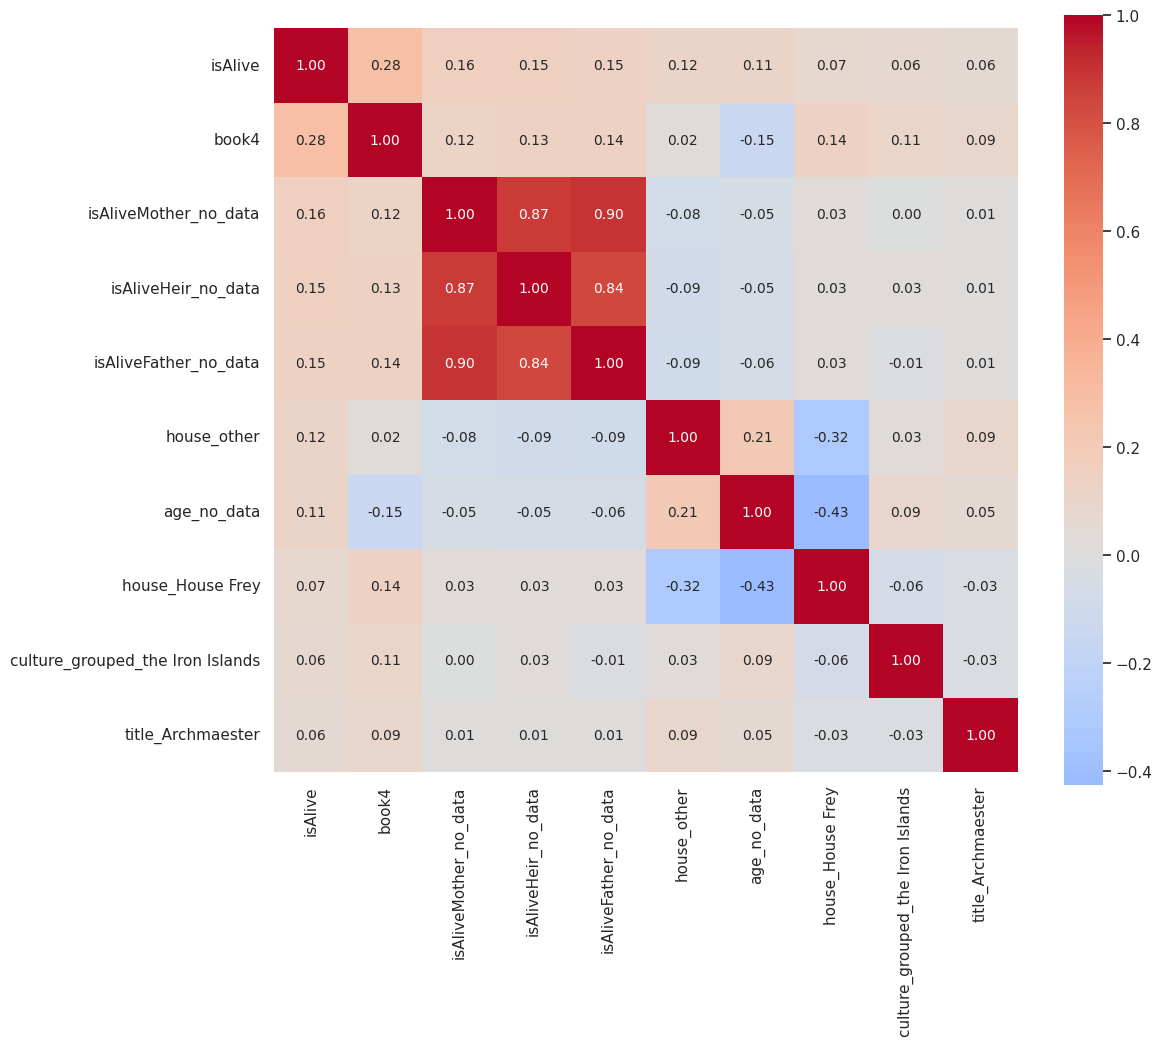

In [ ]:
k = 10
corrmat = data.corr(numeric_only=True)
cols = corrmat.nlargest(k, 'isAlive')['isAlive'].index

cm = np.corrcoef(data[cols].values.T)

sns.set(font_scale=1.0)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cbar=True, annot=True, square=True, fmt='.2f',
            annot_kws={'size': 10},
            yticklabels=cols.values, xticklabels=cols.values,
            cmap='coolwarm', center=0)
plt.show()

Тут видно что isAliveMother_no_data,isAliveHeir_no_data, isAliveFather_no_data сильно коррелируют между собой, поэтому я объединю их в один признак - family_no_data

In [ ]:
data['family_no_data'] = (
    data['isAliveMother_no_data'] |
    data['isAliveFather_no_data'] |
    data['isAliveHeir_no_data']
).astype(int)

data = data.drop(columns=[
    'isAliveMother_no_data', 'isAliveFather_no_data', 'isAliveHeir_no_data'
])

Посмотрим на всю матрицу корреляций

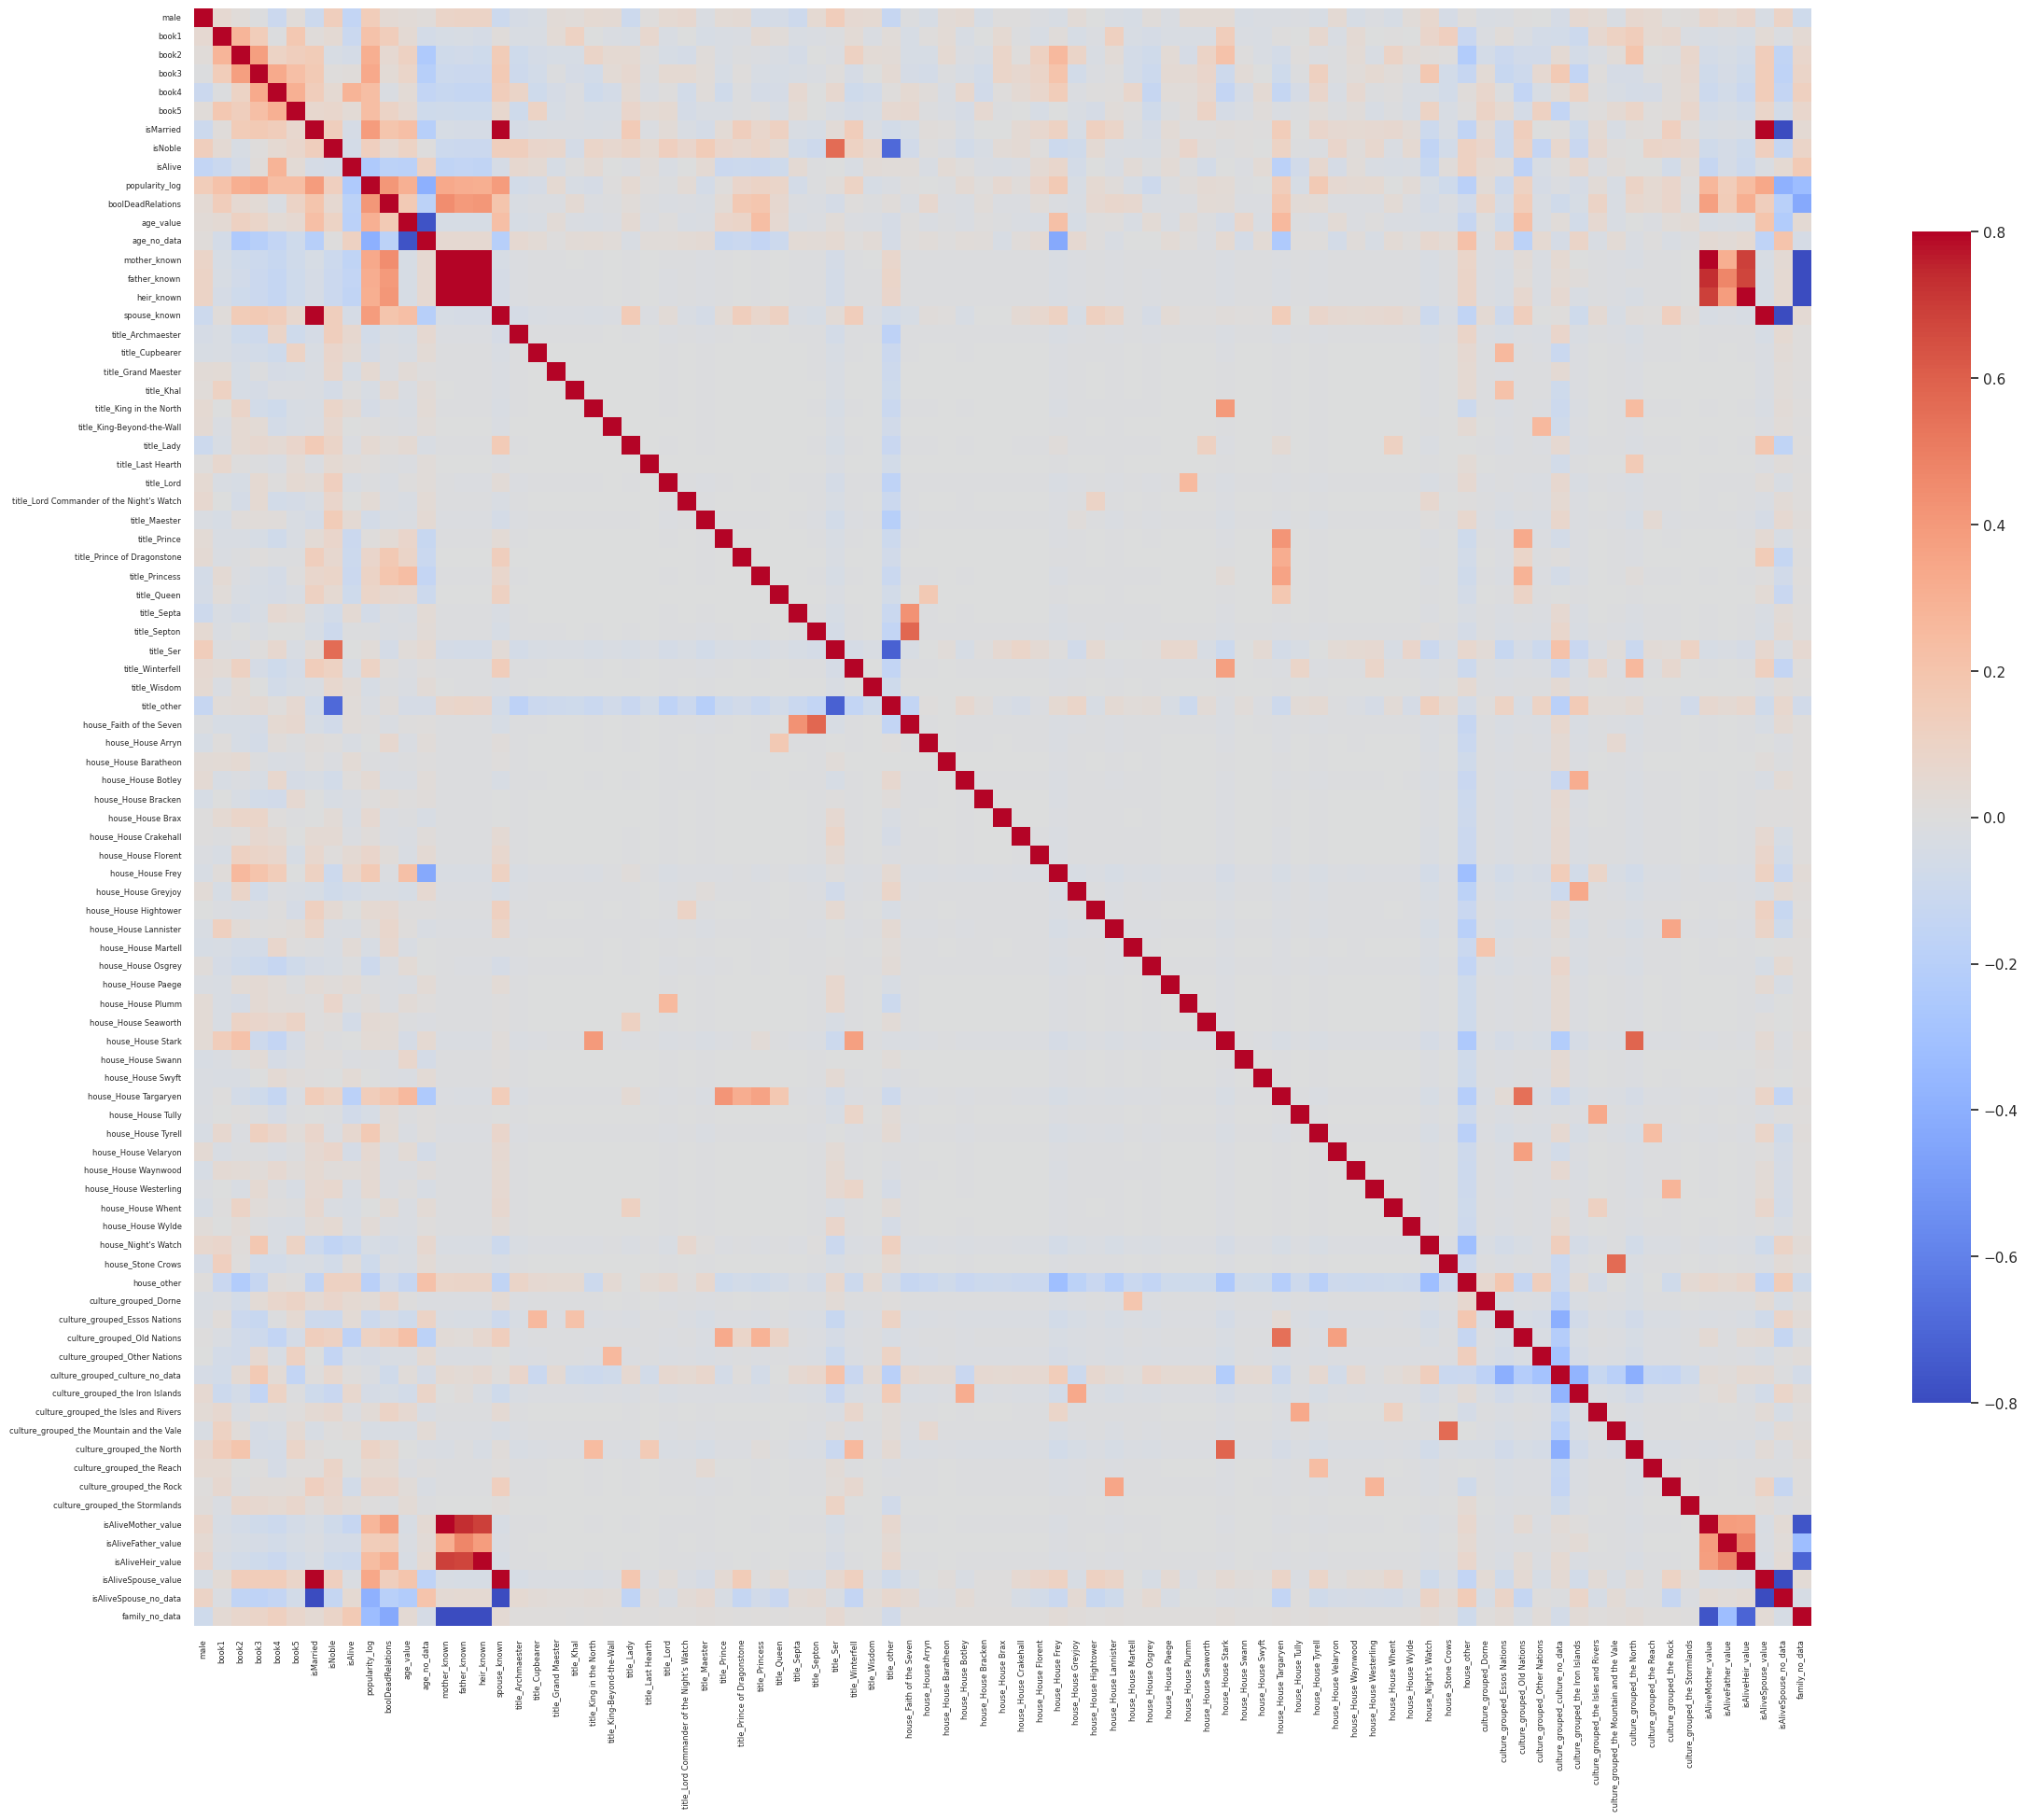

In [ ]:
corrmat = data.corr(numeric_only=True)

plt.figure(figsize=(24, 20))
sns.heatmap(corrmat, vmax=0.8, vmin=-0.8, square=True,
            cmap='coolwarm', center=0,
            cbar_kws={'shrink': 0.7},
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6, rotation=90)
plt.yticks(fontsize=6)
plt.tight_layout()
plt.show()

Получилась похожая ситуация с mother_known, father_known, heir_known, spouse_known, они сильно коррелируют друг с другом, поэтому объединим

In [ ]:
data['relatives_known'] = (
    (data['mother_known'] == 1) |
    (data['father_known'] == 1) |
    (data['heir_known'] == 1) |
    (data['spouse_known'] == 1)
).astype(int)

data = data.drop(columns=['mother_known', 'father_known', 'heir_known', 'spouse_known'])

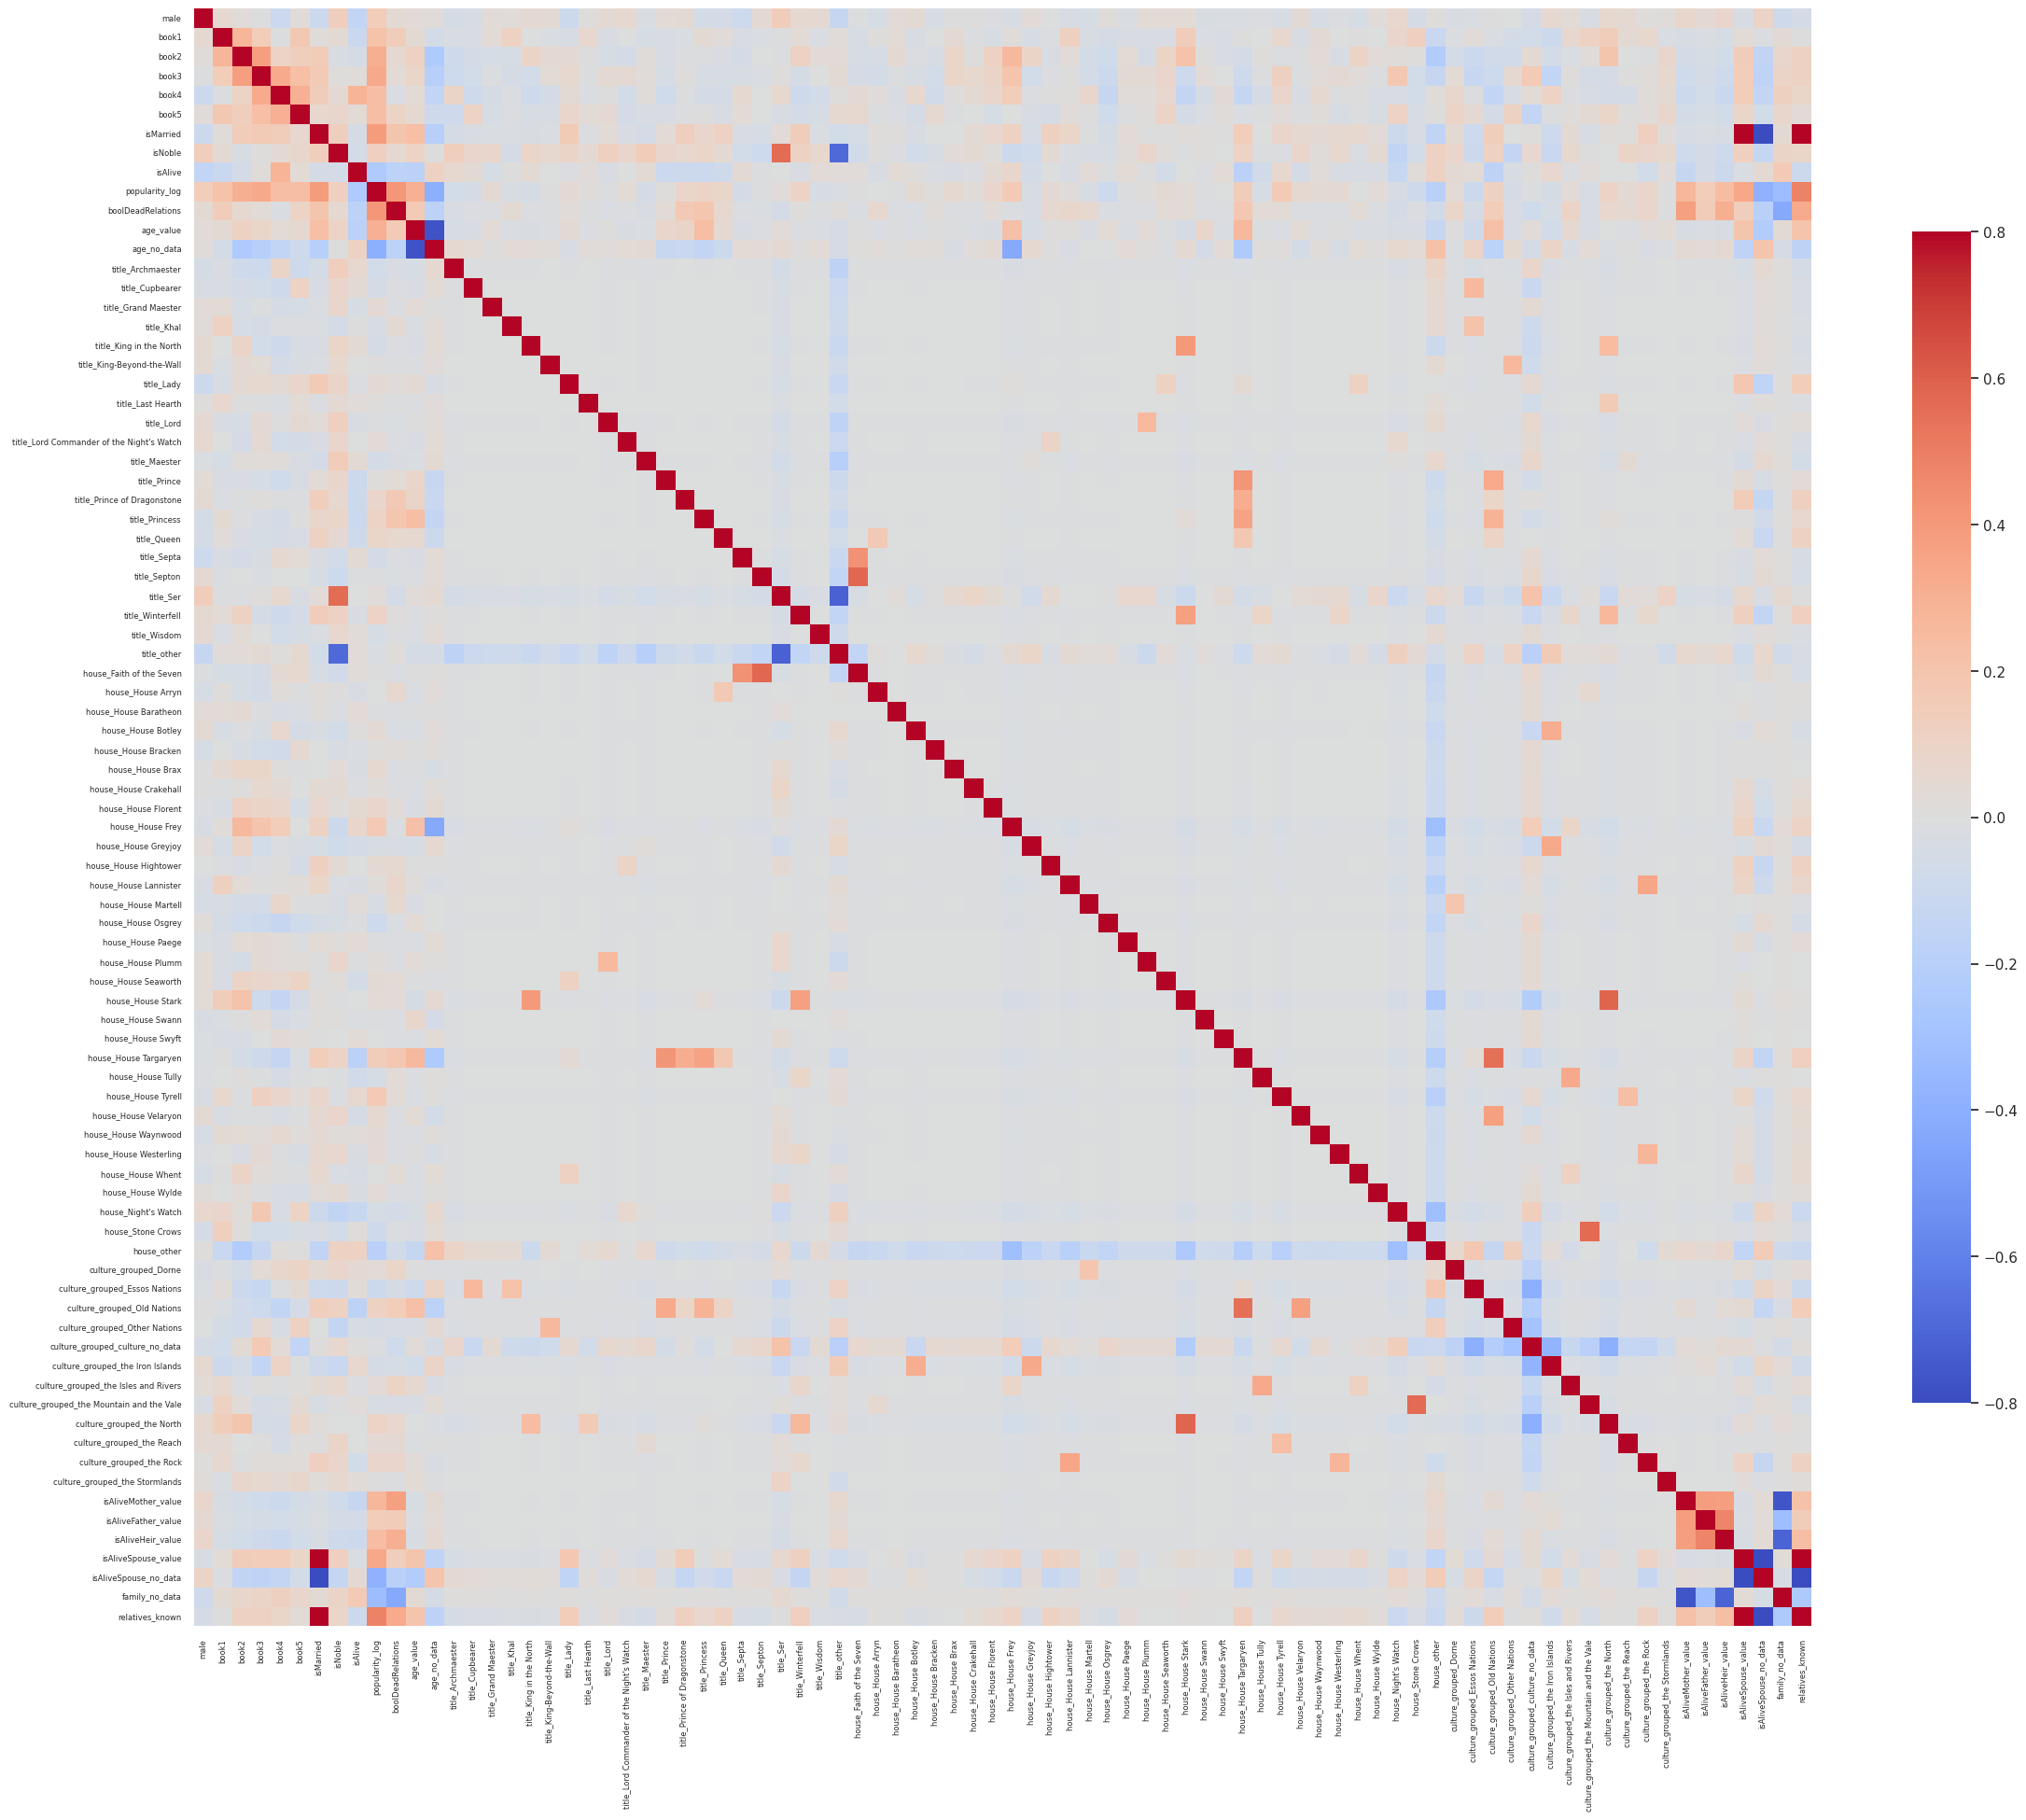

In [ ]:
corrmat = data.corr(numeric_only=True)

plt.figure(figsize=(24, 20))
sns.heatmap(corrmat, vmax=0.8, vmin=-0.8, square=True,
            cmap='coolwarm', center=0,
            cbar_kws={'shrink': 0.7},
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6, rotation=90)
plt.yticks(fontsize=6)
plt.tight_layout()
plt.show()

посмотрим корреляцию цифрами

In [ ]:
corrmat = data.corr(numeric_only=True)
upper = corrmat.where(np.triu(np.ones(corrmat.shape), k=1).astype(bool))

pairs = [(row, col, upper.loc[row, col])
         for col in upper.columns
         for row in upper.index
         if abs(upper.loc[row, col]) > 0.7]
pairs.sort(key=lambda x: -abs(x[2]))

for r, c, v in pairs:
    print(f'{r:50s} <-> {c:50s} r = {v:+.3f}')

isMarried                                          <-> isAliveSpouse_no_data                              r = -1.000
isAliveSpouse_no_data                              <-> relatives_known                                    r = -0.934
isMarried                                          <-> relatives_known                                    r = +0.934
isAliveSpouse_value                                <-> isAliveSpouse_no_data                              r = -0.875
isMarried                                          <-> isAliveSpouse_value                                r = +0.875
isAliveSpouse_value                                <-> relatives_known                                    r = +0.818
age_value                                          <-> age_no_data                                        r = -0.772
isAliveMother_value                                <-> family_no_data                                     r = -0.768
title_Ser                                          <-> title_oth

r=1 - это дубликаты, удаляем

In [ ]:
data = data.drop(columns=['isAliveSpouse_no_data'])

удалим  .._known, они изначально были не особо надежными а теперь и коррелируют с многими и не так сильно влияют

In [ ]:
cols_to_drop = [
    'mother_known', 'father_known', 'heir_known', 'spouse_known',
    'relatives_known'
]
cols_to_drop = [c for c in cols_to_drop if c in data.columns]
data = data.drop(columns=cols_to_drop)

In [ ]:
corrmat = data.corr(numeric_only=True)
upper = corrmat.where(np.triu(np.ones(corrmat.shape), k=1).astype(bool))

pairs = [(row, col, upper.loc[row, col])
         for col in upper.columns
         for row in upper.index
         if abs(upper.loc[row, col]) > 0.7]
pairs.sort(key=lambda x: -abs(x[2]))

for r, c, v in pairs:
    print(f'{r:50s} <-> {c:50s} r = {v:+.3f}')

isMarried                                          <-> isAliveSpouse_value                                r = +0.875
age_value                                          <-> age_no_data                                        r = -0.772
isAliveMother_value                                <-> family_no_data                                     r = -0.768
title_Ser                                          <-> title_other                                        r = -0.723
isAliveHeir_value                                  <-> family_no_data                                     r = -0.710


Эти я оставлю, isMarried и isAliveSpouse_value, отвечают все таки на разные вопросы и если удалить второй мы потеряем 200 строк. Остальные возникли из-за построения признаков и они важны



**Задание 1.8.** Проанализируйте влияние признаков на целевую переменную.

In [ ]:
features = ['male', 'isNoble', 'isMarried', 'boolDeadRelations',
            'book1', 'book2', 'book3', 'book4', 'book5',
            'isAliveSpouse_value', 'family_no_data', 'age_no_data']
for col in features:
    print(f'\n=== {col} ===')
    print(data.groupby(col)['isAlive'].agg(['mean', 'count']))


=== male ===
          mean  count
male                 
0     0.852433    637
1     0.727174    920

=== isNoble ===
             mean  count
isNoble                 
0        0.800687    873
1        0.750000    684

=== isMarried ===
               mean  count
isMarried                 
0          0.786293   1357
1          0.725000    200

=== boolDeadRelations ===
                       mean  count
boolDeadRelations                 
0                  0.794355   1488
1                  0.434783     69

=== book1 ===
           mean  count
book1                 
0      0.797166   1341
1      0.662037    216

=== book2 ===
           mean  count
book2                 
0      0.794651   1047
1      0.745098    510

=== book3 ===
           mean  count
book3                 
0      0.771751    885
1      0.787202    672

=== book4 ===
          mean  count
book4                
0      0.64464    681
1      0.88242    876

=== book5 ===
           mean  count
book5                 
0 

Сделаю более удобное представление в виде таблички

In [ ]:
rows = []
for col in features:
    g = data.groupby(col)['isAlive'].agg(['mean', 'count'])
    rows.append({
        'Признак': col,
        'delta': abs(g['mean'][1] - g['mean'][0]),
        'Меньшая группа': g['count'].min(),
    })

summary = pd.DataFrame(rows).sort_values('delta', ascending=False).round(3)
summary

,Признак,delta,Меньшая группа
10,family_no_data,0.668,17
3,boolDeadRelations,0.360,69
7,book4,0.238,681
4,book1,0.135,216
0,male,0.125,637
11,age_no_data,0.123,279
2,isMarried,0.061,200
1,isNoble,0.051,684
5,book2,0.050,510
8,book5,0.029,514


Очевидно что boolDeadRelations, book4, male, book1, age_no_data оставляем. У них разница ощутимая и размер меньшей группы нормальный.

isMarried, isNoble, book2 тоже оставлю, хотя у них и и небольшая разница, но зато группы у них достаточного размера, а значит они надежные

family_no_data:
самая большая delta, но при этом очень маленькая группа. Проверим дополнительно:

In [ ]:
from scipy.stats import fisher_exact

table = pd.crosstab(data['family_no_data'], data['isAlive'])
print(table)
oddsratio, pval = fisher_exact(table)
print(f'p-value: {pval:.6f}')

isAlive           0     1
family_no_data           
0                15     2
1               330  1210
p-value: 0.000000


Получилось p < 0.01, значит признак реальный - оставляем.

book3, book5, isAliveSpouse_value: удаляю

data = data.drop(columns=['book3', 'book5', 'isAliveSpouse_value'])

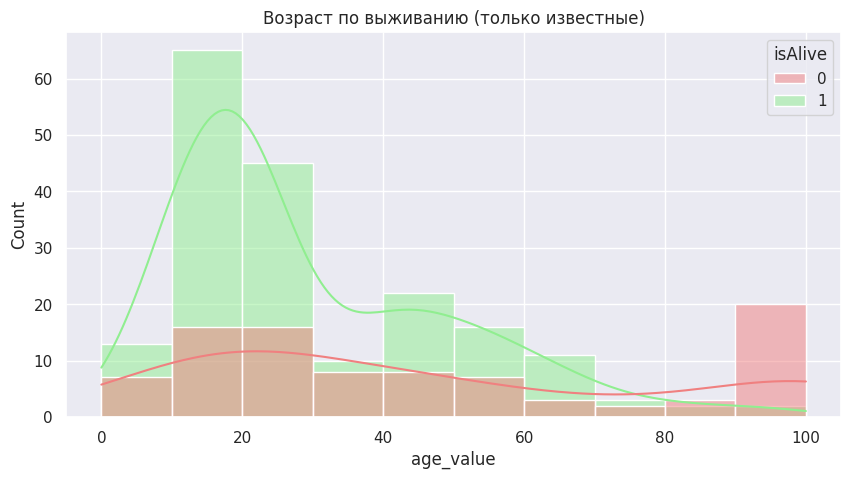

In [ ]:
mask = data['age_no_data'] == 0
plt.figure(figsize=(10, 5))
sns.histplot(data=data[mask], x='age_value', hue='isAlive',
             kde=True, palette={0:'lightcoral', 1:'lightgreen'})
plt.title('Возраст по выживанию (только известные)')
plt.show()

По этому графику можно сделать вывод, что:

В молодом возрасте ~20 лет персонажи выживают чаще.

В возрасте 90+ все умирают (это естественно).

В целом получилось что age_value влияет слабовато, age_no_data оказался сильнее. Но тем не менее его тоже оставим

Посмотрим дома:

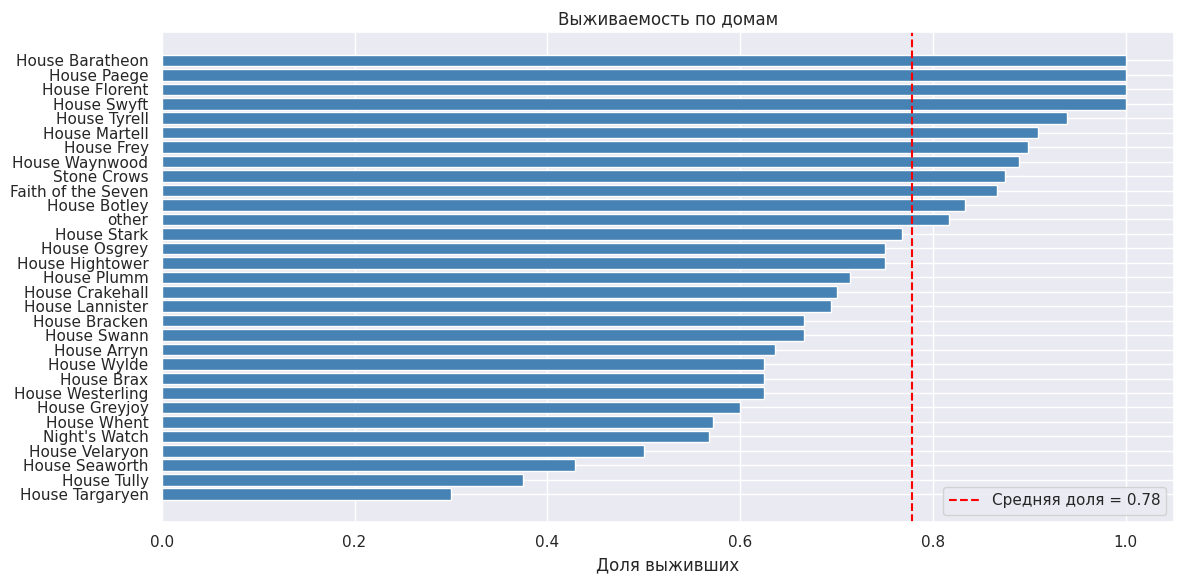

               cat     mean   n
   House Baratheon 1.000000   6
       House Paege 1.000000   7
     House Florent 1.000000  10
       House Swyft 1.000000   7
      House Tyrell 0.939394  33
     House Martell 0.909091  11
        House Frey 0.898876  89
    House Waynwood 0.888889   9
       Stone Crows 0.875000   8
Faith of the Seven 0.866667  15
      House Botley 0.833333  12
             other 0.816684 971
       House Stark 0.767857  56
      House Osgrey 0.750000  20
   House Hightower 0.750000  12
       House Plumm 0.714286   7
   House Crakehall 0.700000  10
   House Lannister 0.694444  36
     House Bracken 0.666667   9
       House Swann 0.666667   6
       House Arryn 0.636364  11
       House Wylde 0.625000   8
        House Brax 0.625000   8
  House Westerling 0.625000   8
     House Greyjoy 0.600000  30
       House Whent 0.571429   7
     Night's Watch 0.568182  88
    House Velaryon 0.500000   8
    House Seaworth 0.428571   7
       House Tully 0.375000   8
   House

In [ ]:
house_stats = []
for c in [col for col in data.columns if col.startswith('house_')]:
    sub = data[data[c] == 1]['isAlive']
    house_stats.append({'cat': c.replace('house_', ''),
                        'mean': sub.mean(), 'n': len(sub)})

house_df = pd.DataFrame(house_stats).sort_values('mean', ascending=False)

plt.figure(figsize=(12, 6))
plt.barh(house_df['cat'], house_df['mean'], color='steelblue')
plt.axvline(data['isAlive'].mean(), color='red', linestyle='--',
            label=f'Средняя доля = {data["isAlive"].mean():.2f}')
plt.xlabel('Доля выживших')
plt.title('Выживаемость по домам')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


print(house_df.to_string(index=False))

Титулы

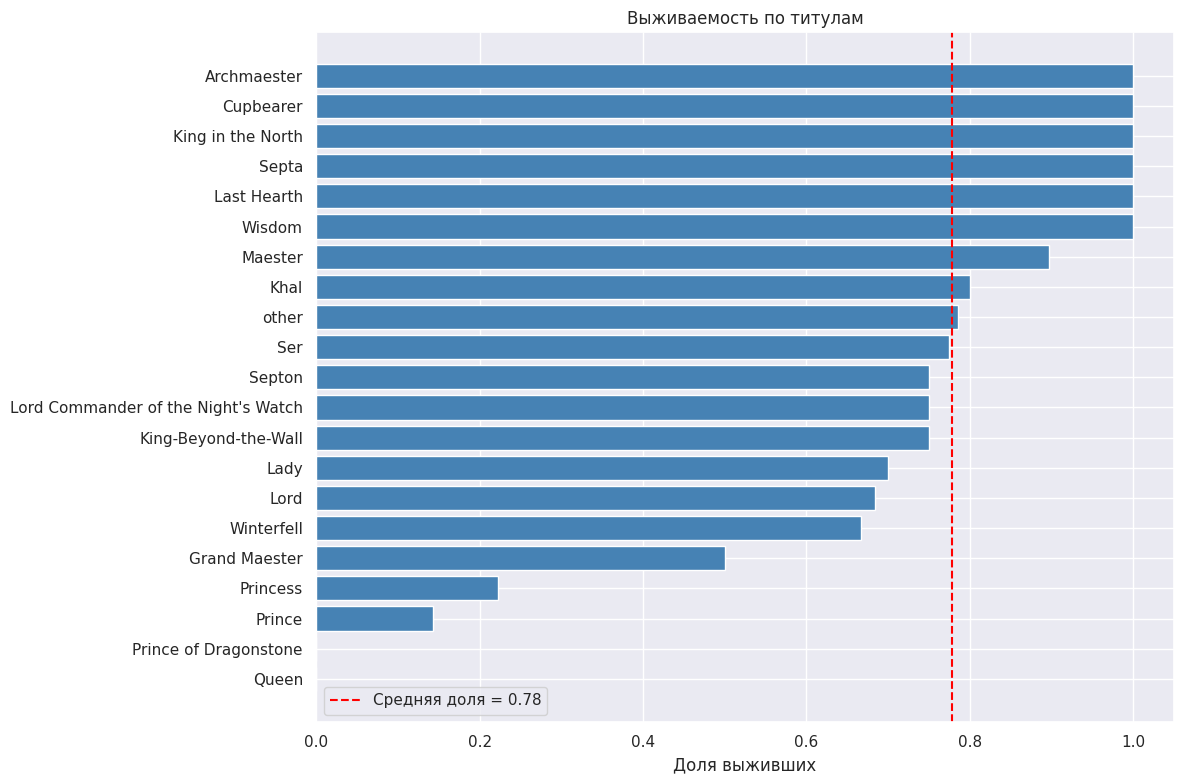

                                cat     mean    n
                        Archmaester 1.000000   21
                          Cupbearer 1.000000    8
                  King in the North 1.000000    9
                              Septa 1.000000    9
                        Last Hearth 1.000000    3
                             Wisdom 1.000000    5
                            Maester 0.896552   29
                               Khal 0.800000    5
                              other 0.785108 1061
                                Ser 0.774510  306
                             Septon 0.750000   16
Lord Commander of the Night's Watch 0.750000    8
               King-Beyond-the-Wall 0.750000    4
                               Lady 0.700000   10
                               Lord 0.684211   19
                         Winterfell 0.666667   15
                      Grand Maester 0.500000    6
                           Princess 0.222222    9
                             Prince 0.142857    7


In [ ]:
title_stats = []
for c in [col for col in data.columns if col.startswith('title_')]:
    sub = data[data[c] == 1]['isAlive']
    title_stats.append({
        'cat': c.replace('title_', ''),
        'mean': sub.mean(),
        'n': len(sub)
    })

title_df = pd.DataFrame(title_stats).sort_values('mean', ascending=False)

plt.figure(figsize=(12, 8))
plt.barh(title_df['cat'], title_df['mean'], color='steelblue')
plt.axvline(data['isAlive'].mean(), color='red', linestyle='--',
            label=f'Средняя доля = {data["isAlive"].mean():.2f}')
plt.xlabel('Доля выживших')
plt.title('Выживаемость по титулам')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(title_df.to_string(index=False))

Культуры

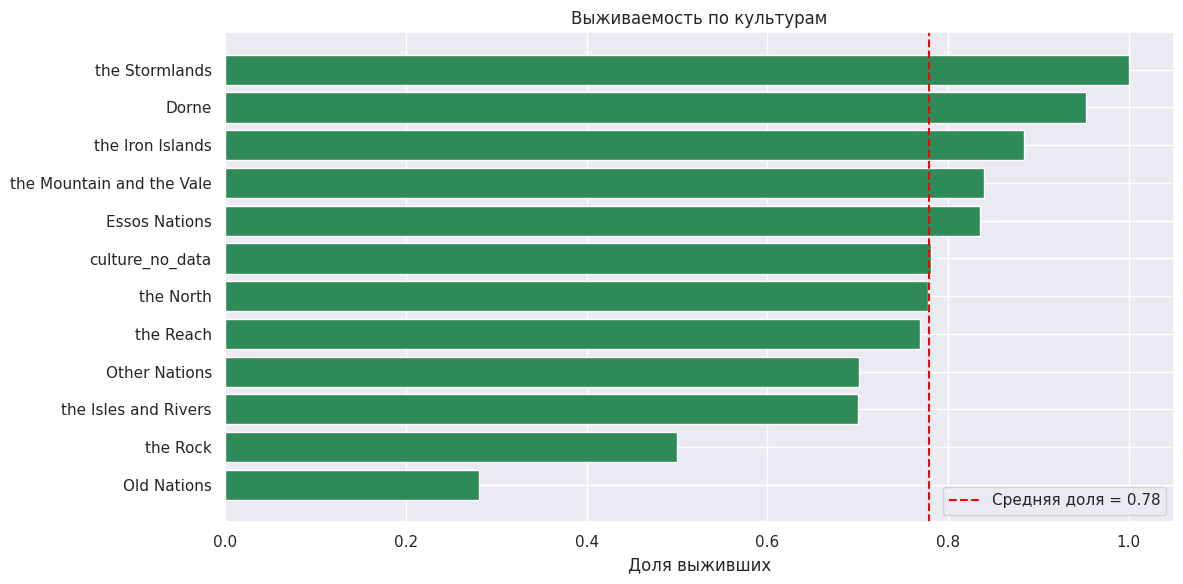

                      cat     mean    n
           the Stormlands 1.000000    4
                    Dorne 0.952381   21
         the Iron Islands 0.884211   95
the Mountain and the Vale 0.840000   25
            Essos Nations 0.834862  109
          culture_no_data 0.781104 1069
                the North 0.777778  108
                the Reach 0.769231   13
            Other Nations 0.701754   57
     the Isles and Rivers 0.700000   10
                 the Rock 0.500000   14
              Old Nations 0.281250   32


In [ ]:
culture_stats = []
for c in [col for col in data.columns if col.startswith('culture_grouped_')]:
    sub = data[data[c] == 1]['isAlive']
    culture_stats.append({
        'cat': c.replace('culture_grouped_', ''),
        'mean': sub.mean(),
        'n': len(sub)
    })

culture_df = pd.DataFrame(culture_stats).sort_values('mean', ascending=False)

plt.figure(figsize=(12, 6))
plt.barh(culture_df['cat'], culture_df['mean'], color='seagreen')
plt.axvline(data['isAlive'].mean(), color='red', linestyle='--',
            label=f'Средняя доля = {data["isAlive"].mean():.2f}')
plt.xlabel('Доля выживших')
plt.title('Выживаемость по культурам')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(culture_df.to_string(index=False))

Все три группы существенны - оставляем

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1557 entries, 1 to 1557
Data columns (total 82 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   male                                       1557 non-null   int64  
 1   book1                                      1557 non-null   int64  
 2   book2                                      1557 non-null   int64  
 3   book3                                      1557 non-null   int64  
 4   book4                                      1557 non-null   int64  
 5   book5                                      1557 non-null   int64  
 6   isMarried                                  1557 non-null   int64  
 7   isNoble                                    1557 non-null   int64  
 8   isAlive                                    1557 non-null   int64  
 9   popularity_log                             1557 non-null   float64
 10  boolDeadRelations            

**Задание 1.9.** Создайте переменные `X`, которая будет хранить только значения признаков, которые вы отобрали для включения в модель, и `y`, которая будет хранить только значения целевой переменной.

In [ ]:
X = data.drop(columns=['isAlive'])
y = data['isAlive']

**Задание 1.10.** Разделите датасет обучащую и валидационные части (train и val) при помощи функции `train_test_split` (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# не забудьте в функции train_test_split задать параметр random_state,
# чтобы обеспечить повторяемость разбиения выборки на train и validation части.
# Это позволит сравнивать метрики моделей с различными методами подготовки признаков

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=True,
    random_state=42,    # фиксируем для воспроизводимости (random_state)
    stratify=y          # сохраняем пропорцию классов
)


Масштабирование

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

## Часть 2. Обучение моделей

В данной части домашнего задания, мы хотим научиться обучать модели для задачи классификации на наших данных.

**Задание 2.1.**


Вы можете работать с одной из предложенных моделей из библиотеки `sklearn`
* LogisticRegression
* RandomForestClassifier
* AdaBoostClassifier
* GaussianProcessClassifier
* GaussianNB
* KNeighborsClassifier
* SVC
* DecisionTreeClassifier


Однако в этом домашнем задании мы предлагаем выбрать и поработать с моделью `LogisticRegression`.

In [ ]:
from sklearn.linear_model import LogisticRegression

Импортируйте остальные модели из библиотеки `sklearn`. Чтобы понять как это сделать, воспользуйтесь официальный документацией `sklearn` $→$ [тык](https://scikit-learn.org/dev/user_guide.html). По ключевому названию модели, вы сможете найти необходимую информацию о том, как можно импортировать модель из библиотеки.

**Задание 2.2.** Обучите модель и сделайте предсказание на тестовой выборке

В качестве примера, обучим модель `LogisticRegression` и сделаем на ней предсказания на тестовой выборке.

In [ ]:
# Шаг 1. создание модели
model = LogisticRegression(max_iter=1000, random_state=42)

# Шаг 2. обучение модели
model.fit(X_train_scaled, y_train)

# Шаг 3. Предсказание на тестовых данных
y_pred = model.predict(X_val_scaled)

обучим еще несколько моделей

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train_scaled, y_train)
y_pred_rf = model_rf.predict(X_val_scaled)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model_kn = KNeighborsClassifier()
model_kn.fit(X_train_scaled, y_train)
y_pred_kn = model_kn.predict(X_val_scaled)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train_scaled, y_train)
y_pred_dt = model_dt.predict(X_val_scaled)

## Часть 3. Оцените качество моделей

Вам необходимо познакомиться с метриками задачи классификации из sklearn. Оцените все модели и выберите лучшую по метрике качества Accuracy.

С метриками классификации вы можете ознакомиться в [Yandex ML Book](https://education.yandex.ru/handbook/ml/article/metriki-klassifikacii-i-regressii).

Для простоты в данном домашнем задании мы будем работать с самой базовой метрикой для задачи классификации - accuracy.

**Задание 3.1.** Вам необходимо посчитать метрику для всех моделей и выбрать лучшую модель.

Сначала импортируем необходимую функцию из библиотеки sklearn для подсчета accuracy.

In [ ]:
from sklearn.metrics import accuracy_score

В качестве примера, посчитаем метрику accuracy для модели `LogisticRegression`

In [ ]:
# Шаг 3 и 4. Предсказание на тестовых данных и оценка предсказания по метрике accuracy

# Logistic Regression
acc_lr = accuracy_score(y_val, y_pred)
print('LogisticRegression: %.4f' % acc_lr)

# Random Forest
acc_rf = accuracy_score(y_val, y_pred_rf)
print('RandomForest: %.4f' % acc_rf)

# KNN
acc_kn = accuracy_score(y_val, y_pred_kn)
print('KNeighbors: %.4f' % acc_kn)

# Decision Tree
acc_dt = accuracy_score(y_val, y_pred_dt)
print('DecisionTree: %.4f' % acc_dt)

# Шаг 4. Оценка предсказания по метрике accuracy
accuracy = accuracy_score(y_val, y_pred)
print("Accuracy : %.4f" % accuracy)

LogisticRegression: 0.8077
RandomForest: 0.8269
KNeighbors: 0.8045
DecisionTree: 0.7436
Accuracy : 0.8077


Возможно, вы решите вернуться на несколько шагов и попробовать другие варианты преобразования и подбора признаков в модель. **Выберите** лучшую модель.

Очевидно, что лучшей из использованных моделей оказалась RandomForest

### Тестовый датасет

В самом начале нашего домашнего задания мы скачивали тестовый датасет. Загрузите его в Pandas DataFrame при помощи функции read_csv

In [ ]:
data = # ...

SyntaxError: invalid syntax (3575586905.py, line 1)

По аналогии с тем, как мы работали с обучающим датасетом, давайте посмотрим в тестовом датасете на статистики признаков с разными типами данных  

In [ ]:
#Подсказка
data_test.loc[data_test['age']<0] # Находим данные с ошибками в дате рождения и возрасте

In [ ]:
#Вы можете аккуратно поправить тестовые данные, воспользовавшись, например следующим кодом:
data_test.loc[1685, 'dateOfBirth'] = 278.
# замены в строке 1685: dateOfBirth -> 278. и age -> 0.
# замены в строке 1869: dateOfBirth -> 299. и age -> 0.

Преобразуйте признаки в тестовом датасете по тому же пайплайну, как вы преобразовывали обучающие данные. Примените вашу лучшую модель на тестовом датасете для получения прогноза целевой переменной `isAlive`

### Файл `submission.csv`

Вам нужно вместо значений в `submission.csv` файле в колонке `isAlive`, подставить свои предсказания и сохранить измененный файл.

In [ ]:
!gdown 1M14conWjAW2QLoyCXbHEAy8bql2f99eF

In [ ]:
submission = pd.read_csv("/content/submission.csv", index_col='S.No')

In [ ]:
submission

Как сохранить измененный Pandas DataFrame в csv файл:

In [ ]:
submission.to_csv("/content/new_submission.csv", index=False)